<a href="https://colab.research.google.com/github/anjali4593/BIS-lab/blob/main/PSO_and_Ant_Colonisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Dataset
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Parameters
np.random.seed(42)
N, G, D = 20, 30, X.shape[1]
w, c1, c2, lam = 0.7, 1.5, 1.5, 0.99
pos = np.random.randint(0, 2, (N, D))
vel = np.random.uniform(-1, 1, (N, D))
for p in pos:
    if p.sum() == 0:
        p[np.random.randint(D)] = 1

model = lambda: make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=2000)
)

# 3. Fitness function
def fitness(p):
    if p.sum() == 0:
        return 1.0
    score = cross_val_score(
        model(), Xtr.loc[:, p.astype(bool)], ytr,
        cv=3, scoring="accuracy"
    ).mean()
    return lam * (1-score) + (1-lam) * p.sum()/D

pbest = pos.copy()
pfit = np.array([fitness(p) for p in pos])
idx = np.argmin(pfit)
gbest, best = pbest[idx].copy(), pfit[idx]
history = []

# 4. Generations
for g in range(1, G+1):
    r1, r2 = np.random.rand(N, D), np.random.rand(N, D)
    vel = w*vel + c1*r1*(pbest-pos) + c2*r2*(gbest-pos)
    prob = 1/(1+np.exp(-np.clip(vel, -50, 50)))
    pos = (np.random.rand(N, D) < prob).astype(int)

    for p in pos:
        if p.sum() == 0:
            p[np.random.randint(D)] = 1

    fit = np.array([fitness(p) for p in pos])
    improved = fit < pfit
    pbest[improved], pfit[improved] = pos[improved], fit[improved]
    idx = np.argmin(pfit)

    if pfit[idx] < best:
        best, gbest = pfit[idx], pbest[idx].copy()

    history.append([g, best, gbest.sum()])
    print(f"Generation {g}: Fitness={best:.5f}, Features={gbest.sum()}")

# 5. Final ML evaluation
features = X.columns[gbest.astype(bool)]
clf = model().fit(Xtr[features], ytr)
pred = clf.predict(Xte[features])

print("\nSelected features:", list(features))
print("Best fitness:", round(best, 5))
print("Test accuracy:", round(accuracy_score(yte, pred), 4))

pd.DataFrame(history, columns=[
    "Generation", "Best_Fitness", "Selected_Features"
]).to_csv("generation_results.csv", index=False)


Generation 1: Fitness=0.02238, Features=15
Generation 2: Fitness=0.02238, Features=15
Generation 3: Fitness=0.02238, Features=15
Generation 4: Fitness=0.01739, Features=13
Generation 5: Fitness=0.01739, Features=13
Generation 6: Fitness=0.01739, Features=13
Generation 7: Fitness=0.01739, Features=13
Generation 8: Fitness=0.01739, Features=13
Generation 9: Fitness=0.01739, Features=13
Generation 10: Fitness=0.01739, Features=13
Generation 11: Fitness=0.01739, Features=13
Generation 12: Fitness=0.01739, Features=13
Generation 13: Fitness=0.01739, Features=13
Generation 14: Fitness=0.01739, Features=13
Generation 15: Fitness=0.01739, Features=13
Generation 16: Fitness=0.01739, Features=13
Generation 17: Fitness=0.01739, Features=13
Generation 18: Fitness=0.01739, Features=13
Generation 19: Fitness=0.01739, Features=13
Generation 20: Fitness=0.01739, Features=13
Generation 21: Fitness=0.01739, Features=13
Generation 22: Fitness=0.01739, Features=13
Generation 23: Fitness=0.01739, Features=

Iteration 10: Best Distance = 31.331
Iteration 20: Best Distance = 31.331
Iteration 30: Best Distance = 31.331
Iteration 40: Best Distance = 31.331
Iteration 50: Best Distance = 31.331
Iteration 60: Best Distance = 31.331
Iteration 70: Best Distance = 31.331
Iteration 80: Best Distance = 31.331
Iteration 90: Best Distance = 31.331
Iteration 100: Best Distance = 31.331

Best Route: 3 -> 5 -> 1 -> 0 -> 2 -> 4 -> 6 -> 3
Best Total Distance: 31.331


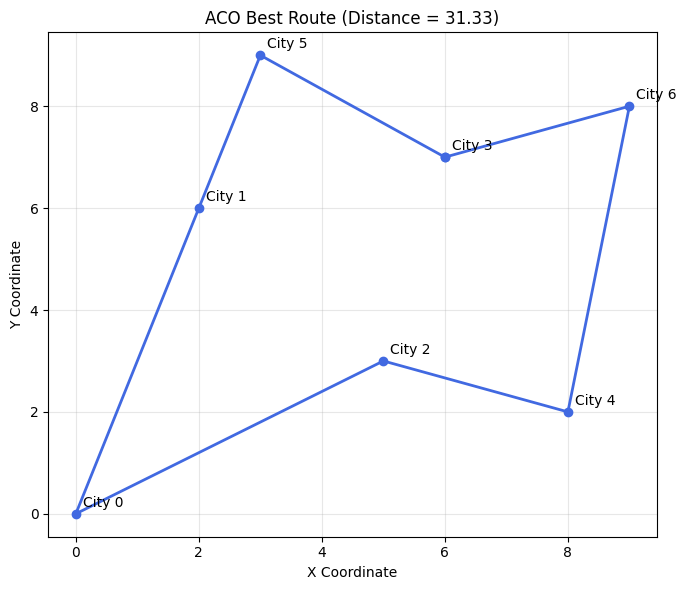

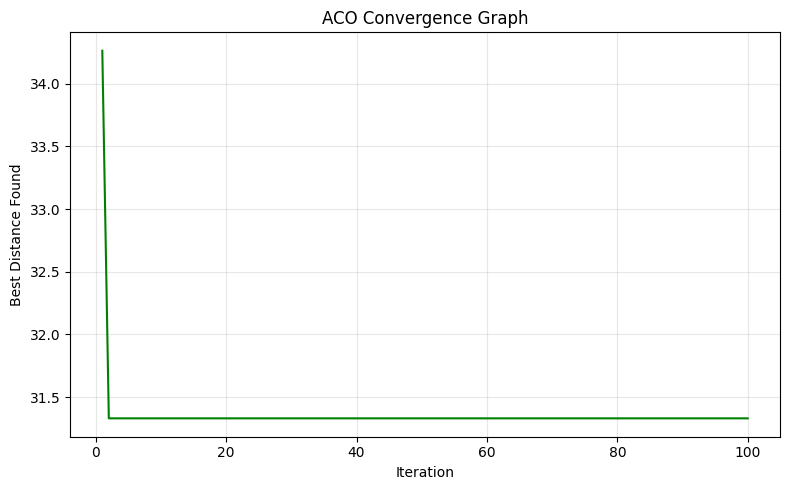

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Cities and coordinates
cities = np.array([
    [0, 0], [2, 6], [5, 3],
    [6, 7], [8, 2], [3, 9], [9, 8]
])
n = len(cities)

# Distance matrix
dist = np.linalg.norm(
    cities[:, None, :] - cities[None, :, :], axis=2
)
heuristic = 1 / (dist + np.eye(n))

# 2. ACO parameters
ants, iterations = 10, 100
alpha, beta = 1.0, 2.0
rho, Q = 0.5, 100
rng = np.random.default_rng(42)

pheromone = np.ones((n, n))
best_route, best_distance = None, float("inf")
history = []

# 3. ACO iterations
for it in range(iterations):
    routes, lengths = [], []

    for ant in range(ants):
        start = rng.integers(n)
        route = [start]
        unvisited = set(range(n))
        unvisited.remove(start)

        while unvisited:
            current = route[-1]
            candidates = np.array(sorted(unvisited))

            weights = (
                pheromone[current, candidates] ** alpha
                * heuristic[current, candidates] ** beta
            )
            probs = weights / weights.sum()
            nxt = rng.choice(candidates, p=probs)

            route.append(nxt)
            unvisited.remove(nxt)

        route.append(start)
        length = sum(
            dist[route[i], route[i + 1]]
            for i in range(n)
        )

        routes.append(route)
        lengths.append(length)

        if length < best_distance:
            best_distance = length
            best_route = route.copy()

    # 4. Pheromone evaporation and deposition
    pheromone *= (1 - rho)

    for route, length in zip(routes, lengths):
        deposit = Q / length
        for i in range(n):
            a, b = route[i], route[i + 1]
            pheromone[a, b] += deposit
            pheromone[b, a] += deposit

    history.append(best_distance)

    if (it + 1) % 10 == 0:
        print(
            f"Iteration {it+1}: "
            f"Best Distance = {best_distance:.3f}"
        )

# 5. Final result
print("\nBest Route:", " -> ".join(map(str, best_route)))
print("Best Total Distance:", round(best_distance, 3))

# 6. Graph 1: Best route
route_points = cities[best_route]

plt.figure(figsize=(7, 6))
plt.plot(
    route_points[:, 0], route_points[:, 1],
    "o-", color="royalblue", linewidth=2
)

for i, (x, y) in enumerate(cities):
    plt.annotate(
        f"City {i}", (x, y),
        xytext=(5, 5), textcoords="offset points"
    )

plt.title(f"ACO Best Route (Distance = {best_distance:.2f})")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Graph 2: Convergence
plt.figure(figsize=(8, 5))
plt.plot(range(1, iterations + 1), history, color="green")
plt.title("ACO Convergence Graph")
plt.xlabel("Iteration")
plt.ylabel("Best Distance Found")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
